In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
recipes = pd.read_csv("../data/raw/RAW_recipes.csv")
interactions = pd.read_csv("../data/raw/RAW_interactions.csv")

print("Datasets loaded successfully!")

Datasets loaded successfully!


In [3]:
print("Recipes Dataset:", recipes.shape)
print("Interactions Dataset:", interactions.shape)

Recipes Dataset: (231637, 12)
Interactions Dataset: (1132367, 5)


In [4]:
recipes.head()

,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6
2,all in the kitchen chili,112140,130,196586,2005-02-25,"['time-to-make', 'course', 'preparation', 'mai...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add choppe...",this modified version of 'mom's' chili was a h...,"['ground beef', 'yellow onions', 'diced tomato...",13
3,alouette potatoes,59389,45,68585,2003-04-14,"['60-minutes-or-less', 'time-to-make', 'course...","[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]",11,['place potatoes in a large pot of lightly sal...,"this is a super easy, great tasting, make ahea...","['spreadable cheese with garlic and herbs', 'n...",11
4,amish tomato ketchup for canning,44061,190,41706,2002-10-25,"['weeknight', 'time-to-make', 'course', 'main-...","[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]",5,['mix all ingredients& boil for 2 1 / 2 hours ...,my dh's amish mother raised him on this recipe...,"['tomato juice', 'apple cider vinegar', 'sugar...",8


In [5]:
interactions.head()

,user_id,recipe_id,date,rating,review
0,38094,40893,2003-02-17,4,Great with a salad. Cooked on top of stove for...
1,1293707,40893,2011-12-21,5,"So simple, so delicious! Great for chilly fall..."
2,8937,44394,2002-12-01,4,This worked very well and is EASY. I used not...
3,126440,85009,2010-02-27,5,I made the Mexican topping and took it to bunk...
4,57222,85009,2011-10-01,5,"Made the cheddar bacon topping, adding a sprin..."


In [6]:
print("Recipe Columns:")
print(recipes.columns.tolist())

print("\nInteraction Columns:")
print(interactions.columns.tolist())

Recipe Columns:
['name', 'id', 'minutes', 'contributor_id', 'submitted', 'tags', 'nutrition', 'n_steps', 'steps', 'description', 'ingredients', 'n_ingredients']

Interaction Columns:
['user_id', 'recipe_id', 'date', 'rating', 'review']


In [7]:
print("Missing values in Recipes:")
print(recipes.isnull().sum())

print("\nMissing values in Interactions:")
print(interactions.isnull().sum())

Missing values in Recipes:
name                 1
id                   0
minutes              0
contributor_id       0
submitted            0
tags                 0
nutrition            0
n_steps              0
steps                0
description       4979
ingredients          0
n_ingredients        0
dtype: int64

Missing values in Interactions:
user_id        0
recipe_id      0
date           0
rating         0
review       169
dtype: int64


In [8]:
print("Duplicate recipes:", recipes.duplicated(subset="id").sum())

print("Duplicate interactions:", 
      interactions.duplicated(subset=["user_id", "recipe_id", "date"]).sum())

Duplicate recipes: 0
Duplicate interactions: 0


rating
0     60847
1     12818
2     14123
3     40855
4    187360
5    816364
Name: count, dtype: int64


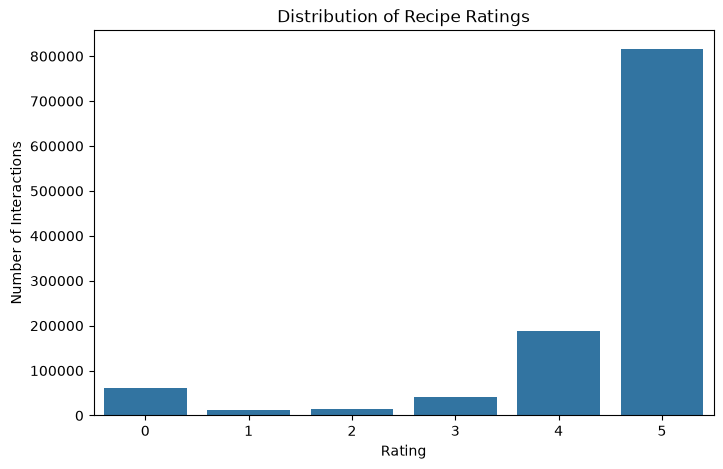

In [9]:
print(interactions["rating"].value_counts().sort_index())

plt.figure(figsize=(8, 5))
sns.countplot(data=interactions, x="rating")
plt.title("Distribution of Recipe Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Interactions")
plt.show()

In [10]:
print("Unique users:", interactions["user_id"].nunique())

print("Unique recipes in interactions:", 
      interactions["recipe_id"].nunique())

print("Unique recipes in recipe dataset:", recipes["id"].nunique())

Unique users: 226570
Unique recipes in interactions: 231637
Unique recipes in recipe dataset: 231637


In [11]:
recipe_ids = set(recipes["id"])
interaction_ids = set(interactions["recipe_id"])

matched = recipe_ids.intersection(interaction_ids)

print("Matched recipe IDs:", len(matched))
print("Unmatched interaction recipe IDs:", 
      len(interaction_ids - recipe_ids))

Matched recipe IDs: 231637
Unmatched interaction recipe IDs: 0


count    2.316370e+05
mean     9.398546e+03
std      4.461963e+06
min      0.000000e+00
25%      2.000000e+01
50%      4.000000e+01
75%      6.500000e+01
max      2.147484e+09
Name: minutes, dtype: float64


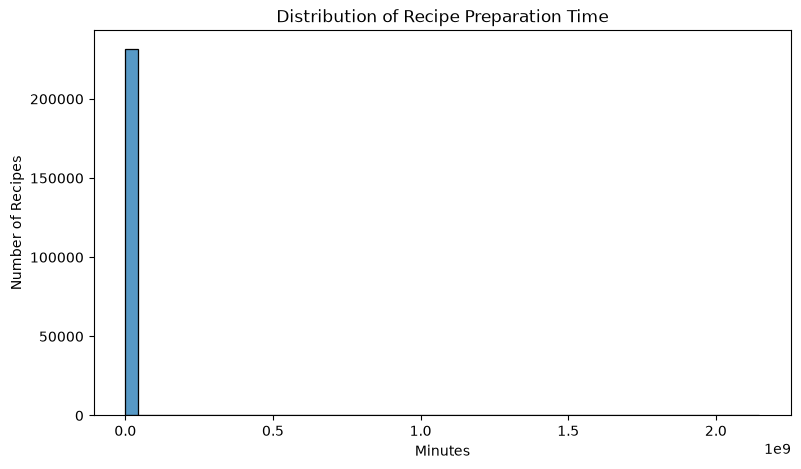

In [12]:
print(recipes["minutes"].describe())

plt.figure(figsize=(9, 5))
sns.histplot(recipes["minutes"], bins=50)
plt.title("Distribution of Recipe Preparation Time")
plt.xlabel("Minutes")
plt.ylabel("Number of Recipes")
plt.show()

In [13]:
extreme_recipes = recipes.nlargest(15, "minutes")[
    ["id", "name", "minutes", "n_ingredients"]
]

print(extreme_recipes.to_string(index=False))

    id                                            name    minutes  n_ingredients
261647                           no bake granola balls 2147483647              8
447963                       how to preserve a husband    1051200              2
291571                          homemade fruit liquers     288000              3
216215   celtic druid s honey mead   meade   metheglin     259260              7
425681                                homemade vanilla     259205              2
 98912                                    peach brandy     216015              4
 70551                                angelica liqueur     201610              7
 12931                                         rumtopf     187200              8
172114                               raspberry liqueur     172810              3
153634                                cinnamon extract     172800              2
  2714                                hard apple cider     167040              8
236340 recipe for elephant s

In [14]:
print("Cooking Time Percentiles:")

print(
    recipes["minutes"].quantile(
        [0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
    )
)

Cooking Time Percentiles:
0.000        0.00
0.250       20.00
0.500       40.00
0.750       65.00
0.900      135.00
0.950      255.00
0.990      903.92
0.999    10095.00
Name: minutes, dtype: float64


In [15]:
zero_ratings = interactions[interactions["rating"] == 0]

print("Zero-rated interactions:", len(zero_ratings))

print("\nSample zero-rated interactions:")
print(
    zero_ratings[
        ["user_id", "recipe_id", "rating", "review"]
    ].head(10).to_string(index=False)
)

print("\nPercentage of zero ratings:",
      round(len(zero_ratings) / len(interactions) * 100, 2), "%")

Zero-rated interactions: 60847

Sample zero-rated interactions:
   user_id  recipe_id  rating                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        review
    124416     120345       0 Just an observation, so I will not rate.  I followed this procedure with strawberries instead of raspberries.  Perhaps this is the reason it did not work well.  Sorry to report that the strawberries I did in August were moldy in October.  They were stored in my downstai

In [16]:
recipes_clean = recipes.copy()
interactions_clean = interactions.copy()

print("Working copies created.")

Working copies created.


In [17]:
recipes_clean["name"] = recipes_clean["name"].fillna("Unknown Recipe")

recipes_clean["description"] = recipes_clean["description"].fillna("")

interactions_clean["review"] = interactions_clean["review"].fillna("")

# Replace unrealistic integer overflow value
recipes_clean.loc[
    recipes_clean["minutes"] == 2147483647, "minutes"
] = np.nan

# Treat zero or negative cooking times as missing
recipes_clean.loc[
    recipes_clean["minutes"] <= 0, "minutes"
] = np.nan

# Remove interactions without an actual numerical rating
interactions_clean = interactions_clean[
    interactions_clean["rating"] > 0
].copy()

print("Preprocessing completed.")
print("Remaining recipes:", len(recipes_clean))
print("Remaining rated interactions:", len(interactions_clean))

Preprocessing completed.
Remaining recipes: 231637
Remaining rated interactions: 1071520


In [18]:
import ast

def parse_list(value):
    try:
        return ast.literal_eval(value) if isinstance(value, str) else []
    except (ValueError, SyntaxError):
        return []

recipes_clean["ingredients_list"] = recipes_clean["ingredients"].apply(parse_list)
recipes_clean["tags_list"] = recipes_clean["tags"].apply(parse_list)

recipes_clean["case_text"] = (
    recipes_clean["name"].fillna("") + " " +
    recipes_clean["description"].fillna("") + " " +
    recipes_clean["ingredients_list"].apply(lambda x: " ".join(x)) + " " +
    recipes_clean["tags_list"].apply(lambda x: " ".join(x))
)

print(recipes_clean[["name", "case_text"]].head(5).to_string(index=False))

                                      name                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                         case_text
arriba   baked winter squash mexican style                                                                                                                                                                                 

In [19]:
recipes_clean.to_csv(
    "../data/processed/recipes_clean.csv", index=False
)

interactions_clean.to_csv(
    "../data/processed/interactions_clean.csv", index=False
)

print("Processed datasets saved successfully!")

Processed datasets saved successfully!


In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors

import time

In [21]:
start_time = time.time()

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=50000,
    min_df=2,
    max_df=0.90,
    dtype=np.float32
)

recipe_vectors = tfidf.fit_transform(
    recipes_clean["case_text"]
)

print("TF-IDF conversion completed!")
print("Matrix shape:", recipe_vectors.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))
print("Time taken:", round(time.time() - start_time, 2), "seconds")

TF-IDF conversion completed!
Matrix shape: (231637, 37417)
Vocabulary size: 37417
Time taken: 39.52 seconds


In [22]:
start_time = time.time()

case_model = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=11,
    n_jobs=-1
)

case_model.fit(recipe_vectors)

print("Case-Based Filtering model trained!")
print("Time taken:", round(time.time() - start_time, 2), "seconds")

Case-Based Filtering model trained!
Time taken: 0.04 seconds


In [25]:

def recommend_similar_recipes(recipe_name, n=10):

    # Normalize spaces in recipe names
    normalized_query = " ".join(recipe_name.lower().split())

    normalized_names = (
        recipes_clean["name"]
        .fillna("")
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

    matches = recipes_clean[
        normalized_names.str.contains(
            normalized_query, regex=False
        )
    ]

    if matches.empty:
        print("Recipe not found! Try a shorter name.")
        return None

    recipe_index = recipes_clean.index.get_loc(matches.index[0])

    distances, indices = case_model.kneighbors(
        recipe_vectors[recipe_index],
        n_neighbors=n + 1
    )

    recommendations = []

    for distance, index in zip(distances[0], indices[0]):

        if index == recipe_index:
            continue

        recipe = recipes_clean.iloc[index]

        recommendations.append({
            "Recipe": recipe["name"],
            "Cooking Time": recipe["minutes"],
            "Ingredients": ", ".join(recipe["ingredients_list"][:5]),
            "Similarity": round(1 - distance, 4)
        })

        if len(recommendations) == n:
            break

    return pd.DataFrame(recommendations)


In [26]:
results = recommend_similar_recipes(
    "arriba baked winter squash mexican style",
    n=10
)

display(results)

,Recipe,Cooking Time,Ingredients,Similarity
0,baked winter squash,40.0,"butternut squash, butter, honey, salt, pepper",0.4706
1,orange winter squash casserole,40.0,"winter squash, butter, cream, salt and pepper,...",0.4647
2,herb roasted winter squash,45.0,"squash, white pearl onions, olive oil, rosemar...",0.4176
3,baked winter squash au gratin,70.0,"winter squash, garlic, cilantro, maple syrup, ...",0.3995
4,mexican squash,35.0,"butter, calabaza squash, onion, garlic cloves,...",0.3912
5,savory winter squash casserole,80.0,"butter, onion, celery, winter squash puree, eggs",0.3904
6,stuffed mexican squash,80.0,"yellow squash, garlic cloves, onion, green pep...",0.3898
7,maple sweet dumpling squash,40.0,"sweet dumpling squash, pure maple syrup, cinna...",0.3892
8,mexican yellow squash casserole,45.0,"yellow squash, onion, butter, pepper, salt",0.3773
9,yellow squash dressing,100.0,"mexican cornbread mix, yellow squash, water, b...",0.3769
